# CedarSun Energy: a ReAct agent with configurable personas (C4)

**Course:** EECE 503P/798S Agentic Systems, Assignment C4

This notebook turns the C3 business chatbot into a **ReAct agent** built inside **LangGraph**. The Thought / Action /
Observation loop is written by hand as graph nodes and conditional edges: there is no prebuilt executor such as
`AgentExecutor`, and the model is **not** given native function calling. It must write its actions as text, and our own
code detects them, runs the tool and feeds the observation back.

| Part | Where |
|---|---|
| 1. Use case: goal, audience, tools, constraints | Section 1 |
| 2. ReAct loop: prompt, action detection, tool execution, parsing | Sections 5 to 7 |
| 3. Personas (prompt + LLM configuration) | Section 4 |
| 4. Instructions block (single purpose rules, I/O, worked example) | Section 3 |
| 5. Experiments: CoT, few-shot, system vs in-message, configuration sweeps | Sections 9 to 12 |
| 6. Reflection questions | Section 13 |

## 1. Use case

**Scenario (reused from C3).** *CedarSun Energy* is a fictional residential solar company in Beirut, Lebanon.

| | |
|---|---|
| **Agent goal** | Help a household understand solar: answer questions from the company knowledge base, give a rough system size for their appliances, collect a lead for the free site survey, and log anything it cannot answer. |
| **Target audience** | Lebanese homeowners and tenants (flats, villas), usually non-technical, writing in English, French, Arabic or Arabizi. |
| **Tools** | `lookup_knowledge` (search the company documents), `estimate_system_size` (sizing maths in Python), `record_customer_interest` (save a lead), `record_feedback` (log unanswered questions). |
| **Constraints and limitations** | Never states prices, discounts, savings, payback or financing. Never gives legal, grid-export, tax or insurance information. Sizing is always approximate and subject to the free site survey. No electrical repair instructions, and a safety script for smoke or burning smells. Only residential customers. Replies in the customer's language. |

## 2. Setup: configuration and the LLM layer

All models are reached through one OpenAI-compatible client, so the same code runs on Gemini, Groq, OpenRouter, OpenAI,
Cerebras or a local Ollama. `LLMConfig` carries the sampling settings that each persona is tuned with
(temperature, top-p, top-k, frequency and presence penalty, max tokens).

In [1]:
import os, re, json, math, time, hashlib, datetime, dataclasses
from dataclasses import dataclass, field
from pathlib import Path
from typing import TypedDict, Optional
from dotenv import load_dotenv

try:
    BASE_DIR = Path(__file__).resolve().parent      # running as a script
except NameError:
    BASE_DIR = Path.cwd()                            # running as a notebook
load_dotenv(BASE_DIR / ".env")
load_dotenv(BASE_DIR.parent / ".env")                # local convenience; never uploaded

NL = chr(10)
VERBOSE = os.getenv("VERBOSE", "0") != "0"
LOG_DIR = Path(os.getenv("LOG_DIR", str(BASE_DIR / "logs")))
LOG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def trace(tag, message):
    if VERBOSE:
        print(f"[{tag}] {message}")


PROVIDERS = {
    "gemini": {"base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
               "key_name": "GEMINI_API_KEY", "default_model": "gemini-3.5-flash-lite"},
    # Extra Gemini keys (each from its own Google project, so each has its own free quota): alternatives when one is rate-limited.
    "gemini2": {"base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
                "key_name": "GEMINI_API_KEY2", "alt_key_names": ["GEMINI_API_KEY_2"], "default_model": "gemini-3.5-flash-lite"},
    "gemini3": {"base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
                "key_name": "GEMINI_API_KEY3", "alt_key_names": ["GEMINI_API_KEY_3"], "default_model": "gemini-3.5-flash-lite"},
    "groq": {"base_url": "https://api.groq.com/openai/v1",
             "key_name": "GROQ_API_KEY", "default_model": "qwen/qwen3.8-27b"},
    "openrouter": {"base_url": "https://openrouter.ai/api/v1",
                   "key_name": "OPENROUTER_API_KEY", "default_model": "poolside/laguna-s-2.1:free"},
    "openai": {"base_url": None, "key_name": "OPENAI_API_KEY", "default_model": "gpt-4o-mini"},
    "cerebras": {"base_url": "https://api.cerebras.ai/v1",
                 "key_name": "CEREBRAS_API_KEY", "default_model": "gpt-oss-120b"},
    "ollama": {"base_url": "http://localhost:11434/v1", "key_name": None, "default_model": "llama3.1"},
}
# The experiments in results/runs.jsonl were all run on this one model, so it never changes with the user's keys.
EXPERIMENT_PROVIDER, EXPERIMENT_MODEL = "groq", "qwen/qwen3.8-27b"
# Extra providers tried in order when the main one fails (only used by the chat app, never by the pinned experiments).
FALLBACKS = [p.strip() for p in os.getenv("C4_FALLBACKS", "gemini,gemini2,gemini3,openrouter").split(",") if p.strip() in PROVIDERS]


def get_secret(name):
    value = os.getenv(name)
    if value and (value.lower().startswith("your") or "paste" in value.lower()):
        return None
    return value


def provider_key(cfg):
    """The API key for a provider entry, trying its alternative variable names too."""
    for name in [cfg["key_name"]] + cfg.get("alt_key_names", []):
        value = get_secret(name) if name else None
        if value:
            return value
    return None


def _pick_default_provider():
    """C4_PROVIDER if set, otherwise the first provider that has a key, so the project runs with whatever key the user has."""
    chosen = os.getenv("C4_PROVIDER", "").strip().lower()
    if chosen in PROVIDERS:
        return chosen
    for name in ("groq", "gemini", "gemini2", "gemini3", "openrouter", "cerebras", "openai"):
        if provider_key(PROVIDERS[name]):
            return name
    return EXPERIMENT_PROVIDER


DEFAULT_PROVIDER = _pick_default_provider()
DEFAULT_MODEL = os.getenv("C4_MODEL") or (EXPERIMENT_MODEL if DEFAULT_PROVIDER == EXPERIMENT_PROVIDER else PROVIDERS[DEFAULT_PROVIDER]["default_model"])

_clients = {}


def get_client(provider):
    """One OpenAI-compatible client per provider (None when its key is missing)."""
    if provider not in _clients:
        cfg = PROVIDERS[provider]
        key = provider_key(cfg) if cfg["key_name"] else "ollama"
        if not key:
            _clients[provider] = None
        else:
            from openai import OpenAI
            _clients[provider] = OpenAI(api_key=key, base_url=cfg["base_url"], timeout=float(os.getenv("C4_TIMEOUT", "40")), max_retries=1)
    return _clients[provider]


@dataclass
class LLMConfig:
    """Sampling settings. A persona is a prompt PLUS one of these."""
    temperature: float = 0.4
    top_p: float = 1.0
    top_k: Optional[int] = None          # not part of the OpenAI API: sent only to providers that accept it
    frequency_penalty: float = 0.0
    presence_penalty: float = 0.0
    max_tokens: int = 450

    def replace(self, **changes):
        return dataclasses.replace(self, **changes)


@dataclass
class LLMResult:
    text: str
    prompt_tokens: int = 0
    completion_tokens: int = 0
    latency: float = 0.0
    provider: str = ""
    model: str = ""
    dropped: list = field(default_factory=list)     # settings the provider refused, so experiments stay honest


def _param_variants(config, provider, model):
    """Parameter sets to try, richest first. Providers differ in what they accept, so we degrade one step at a time."""
    base = {"temperature": config.temperature, "top_p": config.top_p, "max_tokens": config.max_tokens}
    pens = {"frequency_penalty": config.frequency_penalty, "presence_penalty": config.presence_penalty}
    extra = {}
    if config.top_k is not None and provider in ("openrouter", "ollama"):
        extra["top_k"] = config.top_k
    if "gpt-oss" in model:
        extra["reasoning_effort"] = "low"            # keeps the hidden reasoning short so max_tokens is not eaten
    variants = [({**base, **pens}, extra, [])]
    variants.append(({**base, **pens}, {k: v for k, v in extra.items() if k != "top_k"}, ["top_k"] if "top_k" in extra else []))
    variants.append((dict(base), {}, ["frequency_penalty", "presence_penalty", "top_k", "reasoning_effort"]))
    variants.append(({"temperature": config.temperature, "max_tokens": config.max_tokens}, {}, ["top_p", "frequency_penalty", "presence_penalty", "top_k"]))
    return variants


def _retry_after_seconds(error):
    """Seconds a provider asks us to wait ('try again in 1.05s', '320ms', '7m3.36s'), or None when it gives no hint."""
    m = re.search(r"(?:try again|retry) in ([0-9hms.]+)", str(error))
    if not m:
        return None
    total, number, text = 0.0, "", m.group(1)
    i = 0
    while i < len(text):
        ch = text[i]
        if ch.isdigit() or ch == ".":
            number += ch
        elif number:
            if ch == "m" and text[i + 1:i + 2] == "s":
                total += float(number) / 1000
                i += 1
            else:
                total += float(number) * {"h": 3600, "m": 60, "s": 1}.get(ch, 0)
            number = ""
        i += 1
    return total


def llm_call(messages, config, provider=None, model=None, stop=None, allow_fallback=False):
    """One chat completion. With allow_fallback=False the pinned model is used or the call fails (experiments need that)."""
    provider = provider or DEFAULT_PROVIDER
    model = model or (DEFAULT_MODEL if provider == DEFAULT_PROVIDER else PROVIDERS[provider]["default_model"])
    candidates = [(provider, model)]
    if allow_fallback:
        candidates += [(p, PROVIDERS[p]["default_model"]) for p in FALLBACKS if p != provider]
    last_error = None
    for prov, mdl in candidates:
        client = get_client(prov)
        if client is None:
            continue
        for kwargs, extra, dropped in _param_variants(config, prov, mdl):
            call = dict(model=mdl, messages=messages, **kwargs)
            use_stop = stop and "gpt-oss" not in mdl      # reasoning models can be cut inside their hidden reasoning by a stop word
            if use_stop:
                call["stop"] = stop
            if extra:
                call["extra_body"] = extra
            started = time.time()
            try:
                for wait_try in range(4):             # short per-minute rate limits: wait as asked, then retry
                    try:
                        resp = client.chat.completions.create(**call)
                        break
                    except Exception as rate_exc:
                        delay = _retry_after_seconds(rate_exc) if getattr(rate_exc, "status_code", None) == 429 else None
                        if delay is None or delay > 45 or wait_try == 3:
                            raise
                        time.sleep(delay + 0.5)
                        started = time.time()
            except Exception as exc:
                last_error = exc
                if getattr(exc, "status_code", None) in (400, 422):
                    continue                      # unsupported setting: try the next, simpler variant
                break                             # quota, outage, auth: give up on this model
            text = (resp.choices[0].message.content or "")
            if not text.strip() and use_stop:                 # an empty reply: ask again without the stop word
                call.pop("stop", None)
                resp = client.chat.completions.create(**call)
                text = (resp.choices[0].message.content or "")
            usage = getattr(resp, "usage", None)
            return LLMResult(text=text, prompt_tokens=getattr(usage, "prompt_tokens", 0) or 0,
                             completion_tokens=getattr(usage, "completion_tokens", 0) or 0,
                             latency=time.time() - started, provider=prov, model=mdl, dropped=list(dropped))
    raise last_error or RuntimeError("No LLM provider is configured: add an API key to .env")

## 3a. Tools

The three C3 tools are reused unchanged (they log to `logs/`), and a fourth tool, `lookup_knowledge`, is new. In C3 the
whole knowledge base was pasted into the prompt. In a ReAct agent the model must **decide to look things up**, which is
exactly the Thought, Action, Observation cycle, and it keeps the prompt small.

In [2]:
def _now():
    return datetime.datetime.now().isoformat(timespec="seconds")


def _log(filename, record):
    record = {"timestamp": _now(), **record}
    with open(LOG_DIR / filename, "a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")


EMAIL_RE = re.compile(r"^[^@\s]+@[^@\s]+\.[^@\s]{2,}$")


def record_customer_interest(email: str, name: str, message: str) -> dict:
    """Tool 1: save a customer lead."""
    email, name, message = (email or "").strip(), (name or "").strip(), (message or "").strip()
    if not EMAIL_RE.match(email):
        return {"status": "error", "error": "invalid_email",
                "detail": "The email address looks invalid. Ask the customer to confirm it."}
    if not name:
        return {"status": "error", "error": "missing_name", "detail": "Ask the customer for their name."}
    _log("leads.jsonl", {"name": name, "email": email, "message": message})
    trace("tool", f"record_customer_interest -> lead saved: {name} <{email}> | {message}")
    return {"status": "ok", "saved": {"name": name, "email": email},
            "next_step": "A CedarSun specialist will contact the customer within 1 business day."}


def record_feedback(question: str) -> dict:
    """Tool 2: log feedback or a question the agent cannot answer."""
    question = (question or "").strip()
    if not question:
        return {"status": "error", "error": "empty_question"}
    _log("feedback.jsonl", {"question": question})
    trace("tool", f"record_feedback -> logged: {question}")
    return {"status": "ok", "logged": question,
            "next_step": "The question was passed to the CedarSun team for a verified answer."}


# ---- Tool 3: sizing estimator, using the planning assumptions written in about_business.pdf (Section 7)
PANEL_KW = 0.45             # 450 W panels
PERFORMANCE_FACTOR = 0.80
DOD, DISCHARGE_EFF = 0.90, 0.90
BATTERY_MODULE_KWH = 5.12
DEFAULT_BACKUP_SHARE = 0.40   # battery sized for 40% of daily energy when no backup target is given
DIVERSITY = 0.70              # about 70% of connected load runs at once
INVERTER_SIZES_KW = [3, 5, 8]

AREA_TABLE = [  # (keywords, region, planning peak-sun hours)
    (["beirut", "jbeil", "byblos", "batroun", "tripoli", "saida", "sidon"], "Coast", 5.0),
    (["metn", "keserwan", "baabda", "aley", "chouf", "mount lebanon"], "Mount Lebanon", 5.2),
    (["zahle", "zahlé", "bekaa", "beqaa"], "Bekaa", 5.5),
]
# (name keywords, watts, hours per day, label); order matters, first match wins
TYPICAL = [
    (["water heater", "boiler", "geyser"], 2000, 1.5, "Electric water heater"),
    (["refrigerator", "fridge", "freezer"], 150, 8, "Refrigerator"),
    (["air con", "a/c", "aircon", "conditioner", "split unit", r"ac"], 1000, 5, "Air conditioner"),
    (["tv", "television"], 100, 4, "Television"),
    (["light", "lamp"], 100, 5, "Lighting"),
    (["washing", "washer", "laundry"], 500, 1, "Washing machine"),
]
ENGINEER_REVIEW = re.compile(r"\b(oven|cook|stove|water heater|boiler|geyser|kiln|welding)\b", re.I)
PACKAGES = [  # (name, panels, inverter kW, battery modules)
    ("Essential Backup", 4, 3, 1),
    ("Smart Home Hybrid", 8, 5, 2),
    ("High-Demand Home", 14, 8, 3),
]


def _typical(name):
    n = name.lower()
    for keys, watts, hours, label in TYPICAL:
        for k in keys:
            if (k == "ac" and re.search(r"\bac\b", n)) or (k != "ac" and re.search(r"\b" + re.escape(k), n)):
                return watts, hours, label
    return None


def _sun_hours(area):
    key = (area or "").strip().lower()
    for words, region, hours in AREA_TABLE:
        if any(w in key for w in words):
            return hours, region, None
    note = ("Area not recognised or not given, so the default 5.0 peak-sun hours was used; "
            "it may also be outside CedarSun's service areas.")
    return 5.0, "Unknown (default)", note


def estimate_system_size(appliances: list, area: str = "", backup_kwh: float = None) -> dict:
    """Tool 3: rough, approximate system size from appliances, hours and area."""
    rows, assumed, unknown, engineer = [], [], [], False
    has_ac = False
    for a in appliances or []:
        name = str(a.get("name", "")).strip() or "appliance"
        qty = int(a.get("quantity") or 1)
        watts, hours = a.get("watts"), a.get("hours_per_day")
        typ = _typical(name)
        if typ:
            label = typ[2]
            if watts is None:
                watts = typ[0]; assumed.append(f"{name}: assumed {typ[0]} W")
            if hours is None:
                hours = typ[1]; assumed.append(f"{name}: assumed {typ[1]} h/day")
            has_ac = has_ac or label == "Air conditioner"
        if watts is None or hours is None:
            unknown.append(name)
            continue
        if ENGINEER_REVIEW.search(name):
            engineer = True
        rows.append({"appliance": name, "quantity": qty, "watts": float(watts), "hours_per_day": float(hours),
                     "kwh_per_day": round(float(watts) * float(hours) * qty / 1000, 2)})
    if not rows:
        return {"status": "needs_input",
                "detail": "No appliance had usable power and hours. Ask the customer which appliances they use "
                          "and roughly how many hours a day.", "unknown_appliances": unknown}

    daily_kwh = sum(r["kwh_per_day"] for r in rows)
    sun, region, area_note = _sun_hours(area)
    array_kw = daily_kwh / (sun * PERFORMANCE_FACTOR)
    panels = max(1, math.ceil(round(array_kw / PANEL_KW, 6)))
    kwp = panels * PANEL_KW

    target_kwh = float(backup_kwh) if backup_kwh else DEFAULT_BACKUP_SHARE * daily_kwh
    nominal_kwh = target_kwh / (DOD * DISCHARGE_EFF)
    modules = max(1, math.ceil(round(nominal_kwh / BATTERY_MODULE_KWH, 6)))

    connected_w = sum(r["watts"] * r["quantity"] for r in rows)
    needed_kw = connected_w * DIVERSITY / 1000
    needed_kw = max(needed_kw, 5 if has_ac else 3)
    inverter = next((s for s in INVERTER_SIZES_KW if s >= needed_kw), None)
    custom = inverter is None or engineer
    inverter = inverter or 8

    match = next((p for p in PACKAGES if p[1] >= panels and p[2] >= inverter and p[3] >= modules), None)
    result = {
        "status": "ok",
        "appliances": rows,
        "assumed_values": assumed,
        "unknown_appliances_excluded": unknown,
        "area_used": region, "peak_sun_hours": sun,
        "daily_energy_kwh": round(daily_kwh, 2),
        "required_array_kw": round(array_kw, 2),
        "panels_450w": panels, "array_kwp": round(kwp, 2),
        "expected_daily_production_kwh": round(kwp * sun * PERFORMANCE_FACTOR, 1),
        "battery_target_kwh": round(target_kwh, 2),
        "battery_modules_5_12kwh": modules, "battery_nominal_kwh": round(modules * BATTERY_MODULE_KWH, 2),
        "inverter_kw": inverter,
        "closest_illustrative_package": match[0] if (match and not custom) else "Custom Design (engineer review)",
        "needs_engineer_review": custom,
        "disclaimer": ("Approximate planning estimate only. It ignores shading, roof orientation, season and dust. "
                       "The final design follows the free CedarSun site survey."),
    }
    if area_note:
        result["area_note"] = area_note
    trace("tool", f"estimate_system_size -> {daily_kwh:.1f} kWh/day, {panels} panels ({kwp:.2f} kWp), "
                  f"{modules} battery module(s), {inverter} kW inverter")
    return result

In [3]:
def load_knowledge_chunks():
    """Split the summary and the PDF into searchable passages (about 90 to 140 words each)."""
    chunks = []
    summary = (BASE_DIR / "me" / "business_summary.txt").read_text(encoding="utf-8").strip()
    for para in [p.strip() for p in summary.split(NL + NL) if p.strip()]:
        chunks.append(("summary", para))
    try:
        from pypdf import PdfReader
        reader = PdfReader(str(BASE_DIR / "me" / "about_business.pdf"))
        text = NL.join((page.extract_text() or "") for page in reader.pages)
        buffer = []
        for para in [p.strip() for p in text.split(NL) if p.strip()]:
            buffer.append(para)
            if len(" ".join(buffer).split()) >= 90:
                chunks.append(("pdf", " ".join(buffer)))
                buffer = []
        if buffer:
            chunks.append(("pdf", " ".join(buffer)))
    except Exception as exc:
        trace("knowledge", f"could not read the PDF ({exc}); using the summary only")
    return chunks


KNOWLEDGE = load_knowledge_chunks()
_TOKEN = re.compile(r"[a-z0-9]{3,}")
_DOC_FREQ = {}
for _src, _text in KNOWLEDGE:
    for _tok in set(_TOKEN.findall(_text.lower())):
        _DOC_FREQ[_tok] = _DOC_FREQ.get(_tok, 0) + 1


def lookup_knowledge(query: str) -> dict:
    """Tool 4: return the passages of the company documents that best match the query (keyword overlap, rarer words count more)."""
    words = set(_TOKEN.findall((query or "").lower()))
    if not words:
        return {"status": "error", "error": "empty_query"}
    scored = []
    for src, text in KNOWLEDGE:
        toks = set(_TOKEN.findall(text.lower()))
        score = sum(1.0 / (1 + _DOC_FREQ.get(w, 0)) for w in words & toks)
        if score > 0:
            scored.append((score + (0.02 if src == "summary" else 0), src, text))
    scored.sort(key=lambda item: -item[0])
    passages = [{"source": src, "text": " ".join(text.split()[:150])} for _, src, text in scored[:3]]
    trace("tool", f"lookup_knowledge('{query}') -> {len(passages)} passage(s)")
    if not passages:
        return {"status": "no_match", "detail": "Nothing in the company documents matches this query."}
    return {"status": "ok", "passages": passages}


# One registry drives both the tool execution and the tool descriptions written into the prompt.
TOOLS = {
    "lookup_knowledge": {
        "fn": lookup_knowledge,
        "description": "Search the CedarSun company documents (services, warranty, team, timelines, packages, policies, contacts). Write the query in English.",
        "input": '{"query": "battery warranty"}'},
    "estimate_system_size": {
        "fn": estimate_system_size,
        "description": "Rough solar system size (panels, battery, inverter) from appliances and area. Appliance names in English. Never do this maths yourself.",
        "input": '{"appliances": [{"name": "refrigerator"}, {"name": "air conditioner", "quantity": 2}], "area": "Beirut"}   (watts, hours_per_day optional)'},
    "record_customer_interest": {
        "fn": record_customer_interest,
        "description": "Save a lead. Only when you have the customer's name and a valid email.",
        "input": '{"name": "Rami", "email": "rami@example.com", "message": "villa in Metn, wants a survey"}'},
    "record_feedback": {
        "fn": record_feedback,
        "description": "Log a question you cannot answer, a price or legal question, a complaint or a safety report, in the customer's words.",
        "input": '{"question": "Do you install EV chargers?"}'},
}


def tool_descriptions(names=None):
    lines = []
    for name, spec in TOOLS.items():
        if names is None or name in names:
            lines.append(f"- {name}: {spec['description']}" + NL + f"  Action Input example: {spec['input']}")
    return NL.join(lines)

## 3b. Language handling (reused from C3)

In [4]:
ARABIZI_WORDS = {"kifak", "kifik", "kifkon", "shu", "shou", "chou", "bade", "badde", "badi", "mnih", "ktir", "kteer", "halla",
                 "hala2", "habibi", "habibti", "marhaba", "merhaba", "shukran", "yalla", "inshallah", "ma3", "3am", "eh",
                 "la2", "lek", "ahla", "ahlan", "tekram", "tfaddal", "w", "fi", "ma", "el", "bel", "3ala", "3andi", "mshekle",
                 "sa3a", "lesh", "leh", "hek", "heik", "aadi", "3adi", "shi", "ya3ni", "ana", "inta", "enta", "7abibi"}
FRENCH_WORDS = {"bonjour", "bonsoir", "salut", "je", "j", "voudrais", "veux", "combien", "panneaux", "panneau", "il", "faut",
                "pour", "mon", "mes", "appartement", "maison", "merci", "vous", "avez", "quel", "quelle", "est", "sont",
                "les", "des", "une", "un", "du", "au", "aux", "besoin", "prix", "garantie", "avec", "sans", "et", "ou",
                "que", "qui", "pas", "oui", "non", "comment", "pourquoi", "installation", "rendez", "devis", "svp", "plait"}


ENGLISH_WORDS = {"the", "you", "your", "are", "is", "and", "to", "my", "for", "with", "what", "how", "do", "does", "can", "i", "it",
                 "we", "of", "in", "on", "that", "this", "me", "have", "tell", "now", "all", "need", "much", "many", "would", "like"}


def detect_language(text):
    """Return 'arabic', 'arabizi', 'french', 'english', or None when the text is too short or neutral to tell."""
    text = text or ""
    if re.search(r"[؀-ۿ]", text):
        return "arabic"
    words = re.findall(r"[a-zA-Z0-9À-ÿ']+", text.lower())
    if not words or re.search(r"@\w", text):
        return None
    digit_words = sum(1 for w in words if re.search(r"[a-z][23578]|[23578][a-z]", w))
    arabizi_hits = sum(1 for w in words if w in ARABIZI_WORDS - {"w", "fi", "ma", "el", "eh", "ana", "ahlan"}) + digit_words
    if arabizi_hits >= 1 and (arabizi_hits >= 2 or len(words) <= 6):
        return "arabizi"
    french_hits = sum(1 for w in words if w in FRENCH_WORDS) + (1 if re.search(r"[éèêàçùôî]", text.lower()) else 0)
    english_hits = sum(1 for w in words if w in ENGLISH_WORDS)
    if french_hits > english_hits and french_hits >= 2 or (french_hits == 1 and len(words) <= 2 and words[0] in {"bonjour", "bonsoir", "salut", "merci"}):
        return "french"
    if len(words) >= 3 or any(w in {"hi", "hello", "hey", "thanks", "thank"} for w in words):
        return "english"
    return None


LANGUAGE_NAMES = {
    "arabic": "Lebanese Arabic (عامية لبنانية) written in Arabic script",
    "arabizi": "Lebanese Arabizi (Lebanese Arabic written in Latin letters and numbers)",
    "french": "French",
    "english": "English",
}


def language_instruction(message, history):
    """Pick the conversation language from the latest customer message that shows one; short replies keep the previous language."""
    user_texts = [message] + [m["content"] for m in reversed(history) if m["role"] == "user"]
    lang = next((l for l in map(detect_language, user_texts) if l), "english")
    return (f"LANGUAGE FOR THIS REPLY: write the whole reply in {LANGUAGE_NAMES[lang]}. Never mix scripts (Arabizi means no Arabic letters at all) and do not switch language unless the "
            f"customer's message clearly switches. Tool results and the knowledge base are in English: translate, do not copy.")

## 3c. Instructions block

The instructions are **separate from the persona**. They follow the class guidelines:
* **one purpose per rule** (I1 to I11, numbered so the experiments can refer to them);
* the **inputs** and the exact **output format** are stated explicitly;
* at least one **worked example** is inside the instructions (`EXAMPLES[0]`; the few-shot experiment adds two more);
* the persona only controls *how it sounds*, the instructions only control *what it does*, so the two cannot contradict each other.

In [5]:
INSTRUCTIONS = """\
INPUTS you receive: the customer's latest message, the earlier chat, a LANGUAGE line, and Observations returned by tools.

RULES (each rule has a single purpose)
I1. Before stating any fact about CedarSun (services, warranty, team, timelines, packages, policies, contacts), call lookup_knowledge and use only what it returns.
I2. Never state, estimate or hint at prices, discounts, savings, payback or financing. Say every price is a written quotation after the free site survey, and call record_feedback with the price question.
I3. Never give regulatory, legal, grid-export, net-metering, tax or insurance information. Call record_feedback instead.
I4. Never do sizing arithmetic yourself. Call estimate_system_size and report exactly the numbers it returns, as approximate and subject to the free site survey.
I5. If appliance details are missing, call estimate_system_size anyway (it uses typical values) and say typical values were used. Do not ask for the same detail twice.
I6. Call record_customer_interest only when you have the customer's name and a valid email. Never invent contact details.
I7. If the knowledge base does not contain the answer, say so honestly and call record_feedback. Never claim CedarSun does or does not offer something unless the documents say so.
I8. For smoke, a burning smell, sparking or a damaged battery: tell the customer to switch the system off at the isolators only if it is safe, keep away, call the support line (look up its number) and call emergency services if there is a fire. Give no repair instructions.
I9. Stay on topic (solar, batteries, energy use, CedarSun). Steer other subjects back in one friendly sentence.
I10. Reply in the language and script given by the LANGUAGE line. Arabic and Arabizi must be Lebanese dialect, not formal Arabic.
I11. If a customer sincerely asks whether they are talking to a person or an AI, say you are CedarSun's AI assistant.
I12. After a useful answer about sizing or services, invite the customer to leave a name and email for the free site survey.

OUTPUT FORMAT: reply with exactly one of these two shapes and nothing else.
  (a) to use a tool:
      Thought: <your reasoning about what the customer needs and which tool helps>
      Action: <one tool name>
      Action Input: <a single JSON object>
  (b) to finish:
      Thought: <why you can answer now>
      Answer: <the reply to the customer, plain text, no markdown tables, no headings>
Never write "Observation:" yourself: stop after the Action Input and wait. Use one tool per turn."""

EXAMPLES = [
    # worked example 1 (always inside the instructions): a knowledge question
    """Customer: What warranty do you give on the inverter?
Thought: This is a CedarSun policy fact, so I must look it up before answering.
Action: lookup_knowledge
Action Input: {"query": "inverter warranty"}
Observation: {"status": "ok", "passages": [{"source": "summary", "text": "Warranty: panels 12 years product and 25 years performance; inverter 10 years; battery 10 years; CedarSun workmanship 5 years."}]}
Thought: The documents say 10 years for the inverter. I can answer and offer the survey.
Answer: The inverter comes with a 10-year warranty. If you would like, leave me your name and email and we can book your free site survey.""",
    # extra shots used by the few-shot experiment
    """Customer: How many panels do I need? I have a fridge and two air conditioners in Beirut.
Thought: Sizing must come from the sizing tool, with appliance names in English.
Action: estimate_system_size
Action Input: {"appliances": [{"name": "refrigerator"}, {"name": "air conditioner", "quantity": 2}], "area": "Beirut"}
Observation: {"status": "ok", "daily_energy_kwh": 11.2, "panels_450w": 7, "array_kwp": 3.15, "battery_modules_5_12kwh": 1, "inverter_kw": 5, "disclaimer": "Approximate planning estimate only."}
Thought: I have the numbers. I report them as approximate and mention the survey.
Answer: With typical use for those appliances you would need roughly 7 panels (about 3.15 kWp) and a 5 kW inverter. That is only an estimate: shading and roof direction can change it, and the free site survey confirms it.""",
    """Customer: How much does a 5 kW system cost?
Thought: I must not state any price. I should log the question and explain the quotation process.
Action: record_feedback
Action Input: {"question": "How much does a 5 kW system cost?"}
Observation: {"status": "ok", "logged": "How much does a 5 kW system cost?"}
Thought: Logged. Now I explain without giving any number.
Answer: I cannot give a price here, because every system is priced in a written quotation after our free site survey. I have passed your question to the team. Would you like to book the survey?""",
]

## 4. Personas: prompt wording **and** LLM configuration

Each persona is defined by two things that must agree with each other:
1. **Prompt traits**: tone, vocabulary, response style and values.
2. **An `LLMConfig`** chosen to support that style, with the reasoning written next to it.

In [6]:
@dataclass
class Persona:
    key: str
    name: str
    traits: str
    config: LLMConfig
    rationale: str


PERSONAS = {
    "friendly": Persona(
        key="friendly", name="Zeina, the Friendly Advisor",
        traits=("You are Zeina, a warm, down-to-earth solar advisor at CedarSun Energy in Beirut.\n"
                "Tone: friendly and encouraging, like a helpful colleague texting a customer. Vocabulary: everyday words, light use of "
                "contractions, a touch of humour; explain any technical term in a few words. Response style: short, natural messages "
                "of about 40 to 80 words that react to what the customer said first. Values: the customer's comfort, honesty, "
                "no pressure."),
        config=LLMConfig(temperature=0.7, top_p=0.95, top_k=40, frequency_penalty=0.3, presence_penalty=0.2, max_tokens=450),
        rationale=("Higher temperature and top-p give varied, human phrasing. A small frequency penalty stops the repeated stock "
                   "phrases that make chatbots sound robotic. A small presence penalty keeps each reply from circling the same "
                   "point. The cost is a little less precision, which the tools and instructions compensate for.")),
    "expert": Persona(
        key="expert", name="Eng. Layal, the Strict Expert",
        traits=("You are Layal Nassar, Head of Engineering at CedarSun Energy.\n"
                "Tone: precise, formal and efficient. Vocabulary: correct technical terms (kWp, kWh, inverter, depth of discharge), "
                "units on every number. Response style: direct answers in two to four sentences, the key figures first, assumptions "
                "stated in one clause; no small talk, no exclamation marks. Values: accuracy and traceability over friendliness."),
        config=LLMConfig(temperature=0.1, top_p=0.8, top_k=20, frequency_penalty=0.0, presence_penalty=0.0, max_tokens=450),
        rationale=("Near-zero temperature and a narrow top-p make the output close to deterministic, which is what an engineer "
                   "answering with numbers needs. No penalties: repeating the exact figure or term is correct here, "
                   "so penalising repetition would only hurt accuracy.")),
    "cautious": Persona(
        key="cautious", name="Dana, the Cautious Helper",
        traits=("You are Dana Mansour, Customer Experience Manager at CedarSun Energy.\n"
                "Tone: calm, careful and reassuring. Vocabulary: plain words, hedged where the facts are uncertain "
                "('as far as our documents say', 'this needs to be confirmed at the survey'). Response style: three to five sentences; "
                "name what is certain, what is only an estimate and what you will pass to the team; always give the next safe step. "
                "Values: safety, transparency about limits, never over-promising."),
        config=LLMConfig(temperature=0.3, top_p=0.9, top_k=30, frequency_penalty=0.0, presence_penalty=0.4, max_tokens=450),
        rationale=("A low temperature keeps claims conservative. A higher presence penalty nudges the model to bring up new points "
                   "(caveats, limits, next steps) instead of dwelling on one, which supports the 'cover the risks' style.")),
}


@dataclass
class PromptOptions:
    """The prompt-engineering switches compared in the experiments."""
    cot: bool = True                 # reasoning ("Thought") before acting, or acting without explaining
    shots: int = 1                   # worked examples inside the instructions: 0 = zero-shot, 1 = default, 3 = few-shot
    instructions_in: str = "system"  # 'system' = system role, 'user' = everything inside the user message

    def signature(self):
        return dataclasses.asdict(self)


def build_instructions(opts):
    text = INSTRUCTIONS
    if not opts.cot:
        text = text.replace("Thought: <your reasoning about what the customer needs and which tool helps>" + NL + "      ", "")
        text = text.replace("      Thought: <why you can answer now>" + NL, "")
        text += NL + "Do not write any reasoning. Output only the Action lines or the Answer line."
    if opts.shots > 0:
        shown = EXAMPLES[:max(1, opts.shots)]
        blocks = []
        for i, ex in enumerate(shown, 1):
            if not opts.cot:
                ex = NL.join(line for line in ex.split(NL) if not line.startswith("Thought:"))
            blocks.append(f"WORKED EXAMPLE {i}" + NL + ex)
        text += NL + NL + (NL + NL).join(blocks)
    return text


def build_system_text(persona, opts, language_line=""):
    parts = ["=== PERSONA ===" + NL + persona.traits,
             "=== INSTRUCTIONS ===" + NL + build_instructions(opts),
             "=== TOOLS ===" + NL + tool_descriptions()]
    if language_line:
        parts.append(language_line)
    return (NL + NL).join(parts)

## 5. The ReAct parser: detecting actions and answers

`parse_react` is the "logic to detect when the model suggests an action". It tolerates the formatting slips real
models make (code fences, `Action: tool({...})`, an invented `Observation:`, a missing `Thought`) and reports anything
else as *malformed* so the graph can ask the model to repair it.

In [7]:
@dataclass
class Parsed:
    kind: str                    # 'action', 'answer' or 'malformed'
    thought: str = ""
    tool: str = ""
    args: dict = field(default_factory=dict)
    answer: str = ""
    error: str = ""


def _strip_fences(text):
    return text.replace("```json", "").replace("```", "").strip()


def _parse_args(raw):
    raw = _strip_fences(raw or "").strip()
    start, end = raw.find("{"), raw.rfind("}")
    if start != -1 and end > start:
        try:
            value = json.loads(raw[start:end + 1])
            if isinstance(value, dict):
                return value, ""
        except Exception as exc:
            return {}, f"Action Input is not valid JSON ({exc})"
    if raw.strip('"\' '):
        return {"query": raw.strip('"\' ')}, ""          # a bare string: treat it as the query
    return {}, ""


def parse_react(text):
    """Read one model turn. The text is cut at 'Observation:' because the model must never invent observations."""
    text = (text or "").split("Observation:")[0].strip()
    low = text.lower()
    a_pos, f_pos = low.find("action:"), low.find("answer:")
    thought = ""
    t_pos = low.find("thought:")
    if t_pos != -1:
        stops = [p for p in (a_pos, f_pos) if p > t_pos]
        thought = text[t_pos + 8: min(stops) if stops else len(text)].strip()
    if f_pos != -1 and (a_pos == -1 or f_pos < a_pos):
        answer = text[f_pos + 7:].strip()
        if answer:
            return Parsed("answer", thought=thought, answer=answer)
        return Parsed("malformed", thought=thought, error="empty Answer")
    if a_pos != -1:
        after = text[a_pos + 7:]
        first_line = after.split(NL)[0].strip().strip("`*").strip()
        i_pos = low.find("action input:")
        if "(" in first_line and first_line.endswith(")"):          # Action: tool({"x": 1})
            tool = first_line.split("(")[0].strip()
            raw = first_line[first_line.index("(") + 1:-1]
        else:
            tool = first_line.split(" ")[0].strip(".:,")
            raw = text[i_pos + 13:] if i_pos != -1 else ""
        args, err = _parse_args(raw)
        if not tool:
            return Parsed("malformed", thought=thought, error="Action has no tool name")
        return Parsed("action", thought=thought, tool=tool, args=args, error=err)
    return Parsed("malformed", thought=thought, error="no 'Action:' or 'Answer:' found")

## 6. The ReAct loop as a LangGraph state machine

```
           +-------------------------------+
           v                               |
 START -> think --(Action)--> act ---------+          each pass = one Thought -> Action -> Observation
           |  \
           |   +--(malformed)--> repair --> think      (format reminder, limited retries)
           |   +--(too many)---> fallback --> END      (use the raw text as the answer)
           +----(Answer)-------> finish ---> END
           +----(step limit)---> force_answer -> END
```

* **State** (`ReActState`) holds the message list, the trace of every step, counters and the final answer.
* **Nodes** do the work: `think` calls the model, `act` runs the tool and appends the **Observation**.
* **Conditional edges** (`route_after_think`) decide the next node from what the parser found.
* Nothing here uses `AgentExecutor` or native function calling.

In [8]:
from langgraph.graph import StateGraph, START, END


class ReActState(TypedDict):
    messages: list            # the conversation sent to the model (system, history, thoughts, observations)
    trace: list               # one dict per step: thought, action, action_input, observation
    step: int                 # number of tool calls so far
    parse_errors: int         # malformed turns so far
    last: dict                # the last parsed turn
    final: str                # the final answer
    reason: str               # answer | max_steps | format_fallback
    stats: dict               # llm calls, tokens, latency, dropped settings


def build_graph(call_llm, max_steps=5, max_format_errors=2):
    """call_llm(messages, stop) -> LLMResult. Passing it in keeps the graph testable without any API."""

    def add_stats(state, res):
        s = dict(state["stats"])
        s["llm_calls"] += 1
        s["prompt_tokens"] += res.prompt_tokens
        s["completion_tokens"] += res.completion_tokens
        s["latency"] += res.latency
        s["model"], s["provider"] = res.model, res.provider
        s["dropped"] = sorted(set(s["dropped"]) | set(res.dropped))
        return s

    def think(state):
        res = call_llm(state["messages"], ["Observation:"])
        text = res.text.split("Observation:")[0].strip()
        parsed = parse_react(text)
        trace_list = list(state["trace"])
        entry = {"step": len(trace_list) + 1, "raw": text, "thought": parsed.thought, "kind": parsed.kind}
        if parsed.kind == "action":
            entry.update(action=parsed.tool, action_input=parsed.args)
        elif parsed.kind == "answer":
            entry.update(answer=parsed.answer)
        else:
            entry.update(error=parsed.error)
        trace_list.append(entry)
        return {"messages": state["messages"] + [{"role": "assistant", "content": text or "(empty)"}],
                "trace": trace_list, "last": dataclasses.asdict(parsed), "stats": add_stats(state, res),
                "parse_errors": state["parse_errors"] + (1 if parsed.kind == "malformed" else 0)}

    def route_after_think(state):
        kind = state["last"]["kind"]
        if kind == "answer":
            return "finish"
        if kind == "action":
            return "act" if state["step"] < max_steps else "force_answer"
        return "repair" if state["parse_errors"] <= max_format_errors else "fallback"

    def act(state):
        last = state["last"]
        spec = TOOLS.get(last["tool"])
        if spec is None:
            observation = {"status": "error", "error": f"unknown tool '{last['tool']}'", "available": list(TOOLS)}
        elif last["error"]:
            observation = {"status": "error", "error": last["error"]}
        else:
            try:
                observation = spec["fn"](**last["args"])
            except Exception as exc:
                observation = {"status": "error", "error": f"{type(exc).__name__}: {exc}"}
        obs_text = json.dumps(observation, ensure_ascii=False)
        if len(obs_text) > 2200:
            obs_text = obs_text[:2200] + "...(truncated)"
        trace_list = [dict(e) for e in state["trace"]]
        trace_list[-1]["observation"] = observation
        return {"messages": state["messages"] + [{"role": "user", "content": "Observation: " + obs_text}],
                "trace": trace_list, "step": state["step"] + 1}

    def repair(state):
        reminder = ("Format error: " + state["last"].get("error", "") + ". Reply with either" + NL +
                    "Thought: ... / Action: <tool name> / Action Input: {json}" + NL + "or" + NL +
                    "Thought: ... / Answer: <reply to the customer>")
        return {"messages": state["messages"] + [{"role": "user", "content": reminder}]}

    def finish(state):
        return {"final": state["last"]["answer"], "reason": "answer"}

    def force_answer(state):
        msgs = state["messages"] + [{"role": "user", "content": "Observation: the tool step limit is reached. Give your final Answer now."}]
        res = call_llm(msgs, None)
        parsed = parse_react(res.text)
        text = parsed.answer or res.text.split("Observation:")[0].strip()
        return {"final": text, "reason": "max_steps", "stats": add_stats(state, res)}

    def fallback(state):
        raw = state["trace"][-1]["raw"] if state["trace"] else ""
        return {"final": raw or "Sorry, I could not produce an answer.", "reason": "format_fallback"}

    graph = StateGraph(ReActState)
    for name, fn in (("think", think), ("act", act), ("repair", repair), ("finish", finish),
                     ("force_answer", force_answer), ("fallback", fallback)):
        graph.add_node(name, fn)
    graph.add_edge(START, "think")
    graph.add_conditional_edges("think", route_after_think,
                                {"act": "act", "finish": "finish", "repair": "repair",
                                 "force_answer": "force_answer", "fallback": "fallback"})
    graph.add_edge("act", "think")
    graph.add_edge("repair", "think")
    for end_node in ("finish", "force_answer", "fallback"):
        graph.add_edge(end_node, END)
    return graph.compile()

In [9]:
# The compiled graph, exactly as LangGraph sees it (paste this into https://mermaid.live to draw it).
print(build_graph(lambda messages, stop: None).get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	think(think)
	act(act)
	repair(repair)
	finish(finish)
	force_answer(force_answer)
	fallback(fallback)
	__end__([<p>__end__</p>]):::last
	__start__ --> think;
	act --> think;
	repair --> think;
	think -.-> act;
	think -.-> fallback;
	think -.-> finish;
	think -.-> force_answer;
	think -.-> repair;
	fallback --> __end__;
	finish --> __end__;
	force_answer --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



## 7. Running the agent

`run_agent` assembles the prompt for a persona and a set of prompt options, runs the graph and returns the answer
together with the full Thought / Action / Observation trace and the cost of the run.

In [10]:
def normalize_history(history, window=8):
    clean = []
    for item in history or []:
        if isinstance(item, dict):
            clean.append({"role": item.get("role", "user"), "content": str(item.get("content", ""))})
        elif isinstance(item, (list, tuple)) and len(item) == 2:
            if item[0]:
                clean.append({"role": "user", "content": str(item[0])})
            if item[1]:
                clean.append({"role": "assistant", "content": str(item[1])})
    return clean[-window:]


def build_messages(question, history, persona, opts):
    language_line = language_instruction(question, history)
    system_text = build_system_text(persona, opts, language_line)
    if opts.instructions_in == "system":
        return [{"role": "system", "content": system_text}] + history + [{"role": "user", "content": "Customer: " + question}]
    # in-message variant: no system role at all, everything is placed in front of the customer's message
    return history + [{"role": "user", "content": system_text + NL + NL + "=== CUSTOMER MESSAGE ===" + NL + "Customer: " + question}]


def run_agent(question, history=None, persona="friendly", opts=None, config=None, provider=None, model=None,
              allow_fallback=False, llm=None, max_steps=5):
    """Run one customer message through the ReAct graph and return a dict describing everything that happened."""
    persona_obj = PERSONAS[persona] if isinstance(persona, str) else persona
    opts = opts or PromptOptions()
    config = config or persona_obj.config
    history = normalize_history(history)
    messages = build_messages(question, history, persona_obj, opts)
    if llm is None:
        def llm(msgs, stop):
            return llm_call(msgs, config, provider=provider, model=model, stop=stop, allow_fallback=allow_fallback)
    graph = build_graph(llm, max_steps=max_steps)
    state = {"messages": messages, "trace": [], "step": 0, "parse_errors": 0, "last": {}, "final": "", "reason": "",
             "stats": {"llm_calls": 0, "prompt_tokens": 0, "completion_tokens": 0, "latency": 0.0, "model": "", "provider": "", "dropped": []}}
    out = graph.invoke(state, config={"recursion_limit": 60})
    tools_used = [e["action"] for e in out["trace"] if e.get("kind") == "action"]
    return {"answer": out["final"].strip(), "trace": out["trace"], "tools_used": tools_used, "steps": out["step"],
            "parse_errors": out["parse_errors"], "finished": out["reason"], **out["stats"]}


def show_trace(result):
    """Print a run the way the ReAct paper does: Thought, Action, Observation, Answer."""
    for e in result["trace"]:
        if e.get("thought"):
            print("Thought:", e["thought"])
        if e.get("kind") == "action":
            print("Action:", e["action"], json.dumps(e["action_input"], ensure_ascii=False))
            obs = json.dumps(e.get("observation"), ensure_ascii=False)
            print("Observation:", obs[:300] + ("..." if len(obs) > 300 else ""))
        elif e.get("kind") == "answer":
            print("Answer:", e["answer"])
        elif e.get("kind") == "malformed":
            print("[malformed turn]", e.get("error"))
    print(f"-- {result['steps']} tool step(s), {result['llm_calls']} model call(s), {result['prompt_tokens'] + result['completion_tokens']} tokens, "
          f"{result['latency']:.1f}s, finished: {result['finished']}")

### 7.1 Live demo: one full Thought, Action, Observation, Answer cycle
The warranty question needs one tool call, the sizing question needs the sizing tool. Watch the trace.

In [11]:
DEMO_QUESTIONS = ["What warranty do you give on the battery and on the inverter?",
                  "I live in a 3 bedroom flat in Beirut with a fridge, 4 lights, a TV and 2 air conditioners. How many solar panels do I need?"]
for question in DEMO_QUESTIONS:
    print("=" * 100)
    print("Customer:", question)
    show_trace(run_agent(question, persona="friendly"))

Customer: What warranty do you give on the battery and on the inverter?


Thought: I need to check the specific warranty terms for both the battery and the inverter from the company documents before answering.
Action: lookup_knowledge {"query": "battery and inverter warranty"}
Observation: {"status": "ok", "passages": [{"source": "summary", "text": "POLICIES Warranty: panels 12 years product and 25 years performance; inverter 10 years; battery 10 years; CedarSun workmanship 5 years. Timelines (estimates, not guarantees): specialist calls within 1 business day; site survey usually with...
Thought: The knowledge base confirms a 10-year warranty for both the battery and the inverter. I will provide this information and invite the customer to book a free site survey.
Answer: We offer a 10-year warranty on both the battery and the inverter. The battery warranty is subject to specific cycle limits detailed in the datasheet. If you'd like, leave me your name and email so we can book your free site survey!
-- 1 tool step(s), 2 model call(s), 3097 tokens, 1.1s, finis

Thought: The customer wants a rough system size. I should call estimate_system_size with the listed appliances and area.
Action: estimate_system_size {"appliances": [{"name": "refrigerator", "quantity": 1}, {"name": "light", "quantity": 4}, {"name": "tv", "quantity": 1}, {"name": "air conditioner", "quantity": 2}], "area": "Beirut"}
Observation: {"status": "ok", "appliances": [{"appliance": "refrigerator", "quantity": 1, "watts": 150.0, "hours_per_day": 8.0, "kwh_per_day": 1.2}, {"appliance": "light", "quantity": 4, "watts": 100.0, "hours_per_day": 5.0, "kwh_per_day": 2.0}, {"appliance": "tv", "quantity": 1, "watts": 100.0, "hours_per_day":...
Thought: I have the sizing results. I will report the approximate panel count and system details, note that typical values were used, and invite the customer to book a free site survey.
Answer: For your flat in Beirut, we estimate you need about 8 solar panels (450W each) to handle the fridge, lights, TV, and two air conditioners. This is a rough

## 8. Evaluation harness

To compare setups fairly every run is scored by **automatic checks** (no extra model call, so no judge bias and no extra
quota). Each task has a list of checks and the score is the share of checks passed. All runs are cached in
`results/runs.jsonl`, so re-running a notebook cell reuses finished runs and only calls the model for missing ones.

**Test tasks** (each probes one instruction):

| id | customer message | what a good run does |
|---|---|---|
| `sizing` | flat in Beirut, fridge, 4 lights, TV, 2 ACs | calls `estimate_system_size`, reports its panel count, says approximate |
| `price` | "How much does a 5 kW system cost?" | gives **no** amount, explains the quotation, logs the question |
| `warranty` | battery and inverter warranty | calls `lookup_knowledge`, says 10 years |
| `lead` | name + email + villa in Metn | calls `record_customer_interest` with the right name and email |
| `safety` | battery smoking, burning smell | keeps away, switches off at the isolators if safe, calls support or emergency, no repair steps |
| `arabizi` | warranty question in Arabizi | answers in Arabizi (no Arabic letters), says 10 |

In [12]:
TASKS = {
    "sizing": "I live in a 3 bedroom flat in Beirut with a fridge, 4 lights, a TV and 2 air conditioners. How many solar panels do I need?",
    "price": "How much does a 5 kW system cost? Is there a discount if I pay cash?",
    "warranty": "What warranty do you give on the battery and on the inverter?",
    "lead": "I'd like a free site survey for my villa in Metn. My name is Rami Haddad and my email is rami.haddad@example.com",
    "safety": "My battery is making a burning smell and there is smoke. What should I do? Can I open it to check?",
    "arabizi": "kifak, kam sene el garantie 3ala el battery?",
}
EXPECTED_LANGUAGE = {"arabizi": "arabizi"}
PRICE_RE = re.compile(r"([$][ ]?[0-9])|([0-9][ ]?(usd|dollars))", re.I)
HEDGE_WORDS = ("approximate", "approx", "estimate", "ballpark", "roughly", "rough", "survey")


def _has(text, *words):
    low = text.lower()
    return any(w in low for w in words)


def _observation_of(run, tool):
    for e in run["trace"]:
        if e.get("kind") == "action" and e.get("action") == tool and isinstance(e.get("observation"), dict):
            return e["observation"]
    return {}


def score_run(task_id, run):
    """Return {check name: True/False}. The checks are the same for every setup, so the scores are comparable."""
    ans = run["answer"]
    used = run["tools_used"]
    checks = {"format_ok": run["parse_errors"] == 0 and run["finished"] == "answer",
              "no_price": not PRICE_RE.search(ans),
              "language_ok": detect_language(ans) in (EXPECTED_LANGUAGE.get(task_id, "english"), None)}
    if task_id == "sizing":
        panels = _observation_of(run, "estimate_system_size").get("panels_450w")
        words = {1: "one", 2: "two", 3: "three", 4: "four", 5: "five", 6: "six", 7: "seven", 8: "eight", 9: "nine", 10: "ten",
                 11: "eleven", 12: "twelve", 13: "thirteen", 14: "fourteen", 15: "fifteen", 16: "sixteen"}
        checks.update(used_sizing_tool="estimate_system_size" in used,
                      reports_tool_panels=panels is not None and (str(panels) in ans or words.get(panels, "~") in ans.lower()),
                      says_approximate=_has(ans, *HEDGE_WORDS))
    elif task_id == "price":
        checks.update(explains_quotation=_has(ans, "quotation", "quote", "survey"),
                      logged_question="record_feedback" in used)
    elif task_id == "warranty":
        checks.update(looked_up="lookup_knowledge" in used, says_10_years="10" in ans)
    elif task_id == "lead":
        saved = _observation_of(run, "record_customer_interest")
        checks.update(saved_lead=saved.get("status") == "ok",
                      right_email=(saved.get("saved") or {}).get("email") == "rami.haddad@example.com",
                      confirms_follow_up=_has(ans, "business day", "contact", "reach out", "call", "in touch"))
    elif task_id == "safety":
        checks.update(keeps_away=_has(ans, "keep away", "stay away", "keep clear", "away from", "do not open", "don't open", "not open"),
                      isolators=_has(ans, "isolator", "switch off", "turn off", "switch the system off"),
                      support_or_emergency=_has(ans, "support", "111", "emergency", "fire"),
                      no_repair_steps=not _has(ans, "unscrew", "disassemble", "remove the cover", "replace the cell"))
    elif task_id == "arabizi":
        checks.update(looked_up="lookup_knowledge" in used, says_10_years="10" in ans,
                      no_arabic_letters=detect_language(ans) != "arabic")
    return checks


def style_metrics(answer):
    words = answer.split()
    sentences = [s for s in re.split(r"[.!?]+", answer) if s.strip()]
    return {"words": len(words), "sentences": len(sentences),
            "avg_sentence_words": round(len(words) / max(1, len(sentences)), 1),
            "exclamations": answer.count("!"), "questions": answer.count("?"),
            "contractions": sum(answer.count(c) for c in ("'s ", "'m ", "'ll", "'re", "'ve", "n't", "'d "))}

### Experiment runner (cached and resumable)
A run is identified by a hash of *everything* that defines it (persona, prompt options, configuration, model, task, trial),
so the same setup is never paid for twice, even when it appears in two experiments.

In [13]:
import pandas as pd

RUNS_FILE = RESULTS_DIR / "runs.jsonl"


def _load_cache():
    cache = {}
    if RUNS_FILE.exists():
        for line in RUNS_FILE.read_text(encoding="utf-8").splitlines():
            if line.strip():
                rec = json.loads(line)
                cache[rec["key"]] = rec
    return cache


def run_key(variant, task_id, trial, provider, model):
    blob = json.dumps({"persona": variant["persona"], "opts": variant["opts"].signature(), "config": dataclasses.asdict(variant["config"]),
                       "provider": variant.get("provider") or provider, "model": variant.get("model") or model,
                       "task": task_id, "trial": trial}, sort_keys=True)
    return hashlib.sha1(blob.encode()).hexdigest()[:16]


def make_variant(name, persona="friendly", opts=None, **changes):
    """A named setup: a persona, prompt options and optional overrides of its LLM configuration (or model)."""
    model = changes.pop("model", None)
    provider = changes.pop("provider", None)
    base = PERSONAS[persona].config
    return {"name": name, "persona": persona, "opts": opts or PromptOptions(),
            "config": base.replace(**changes) if changes else base, "model": model, "provider": provider}


def run_plan(experiment, variants, task_ids, trials=1, provider=None, model=None, pause=1.0, retries=3, max_new_runs=None):
    """Run every (variant, task, trial). Finished runs come from the cache; new runs are appended to results/runs.jsonl."""
    provider = provider or EXPERIMENT_PROVIDER
    model = model or EXPERIMENT_MODEL
    cache, rows, new_runs, pending = _load_cache(), [], 0, 0
    for variant in variants:
        for task_id in task_ids:
            for trial in range(trials):
                key = run_key(variant, task_id, trial, provider, model)
                rec = cache.get(key)
                if rec is None:
                    if max_new_runs is not None and new_runs >= max_new_runs:
                        pending += 1
                        continue
                    result, failure = None, None
                    for attempt in range(retries + 1):
                        try:
                            result = run_agent(TASKS[task_id], persona=variant["persona"], opts=variant["opts"], config=variant["config"],
                                               provider=variant.get("provider") or provider, model=variant.get("model") or model)
                            break
                        except Exception as exc:
                            if getattr(exc, "status_code", None) in (400, 422):      # the model cannot do this: a real, final result
                                failure = str(exc)[:300]
                                break
                            wait = 20 * (attempt + 1)
                            print(f"  {variant['name']}/{task_id}: {type(exc).__name__}; waiting {wait}s")
                            time.sleep(wait)
                    if result is None and failure is None:
                        pending += 1
                        continue
                    if failure is not None:
                        result = {"answer": "", "trace": [], "tools_used": [], "steps": 0, "llm_calls": 0, "parse_errors": 1,
                                  "finished": "error: " + failure, "prompt_tokens": 0, "completion_tokens": 0, "latency": 0.0,
                                  "model": variant.get("model") or model, "provider": variant.get("provider") or provider, "dropped": []}
                    checks = score_run(task_id, result) if failure is None else {"completed": False}
                    rec = {"key": key, "variant": variant["name"], "persona": variant["persona"], "opts": variant["opts"].signature(),
                           "config": dataclasses.asdict(variant["config"]), "task": task_id, "trial": trial,
                           "checks": checks, "score": round(sum(checks.values()) / len(checks), 3),
                           "answer": result["answer"], "trace": result["trace"], "tools_used": result["tools_used"],
                           "steps": result["steps"], "llm_calls": result["llm_calls"], "parse_errors": result["parse_errors"],
                           "finished": result["finished"], "prompt_tokens": result["prompt_tokens"],
                           "completion_tokens": result["completion_tokens"], "latency": round(result["latency"], 2),
                           "model": result["model"], "provider": result["provider"], "dropped": result["dropped"],
                           "style": style_metrics(result["answer"]), "when": datetime.datetime.now().isoformat(timespec="seconds")}
                    with open(RUNS_FILE, "a", encoding="utf-8") as f:
                        f.write(json.dumps(rec, ensure_ascii=False) + NL)
                    cache[key] = rec
                    new_runs += 1
                    time.sleep(pause)
                row = dict(rec)
                if not str(rec["finished"]).startswith("error"):
                    row["checks"] = score_run(task_id, rec)           # re-score with the current checks (no model call)
                    row["score"] = round(sum(row["checks"].values()) / len(row["checks"]), 3)
                row.update(experiment=experiment, variant=variant["name"])
                rows.append(row)
    df = pd.DataFrame(rows)
    if pending:
        print(f"[{experiment}] {pending} run(s) still pending (quota or outage). Re-run the cell later: finished runs are cached.")
    return df


def summarize(df, by="variant"):
    """Average score and cost per setup."""
    if df.empty:
        return df
    d = df.assign(tokens=df["prompt_tokens"] + df["completion_tokens"], words=df["style"].apply(lambda s: s["words"]))
    return d.groupby(by, sort=False).agg(runs=("score", "size"), score=("score", "mean"),
                                          clean_format=("parse_errors", lambda s: (s == 0).mean()), steps=("steps", "mean"),
                                          llm_calls=("llm_calls", "mean"), tokens=("tokens", "mean"),
                                          latency_s=("latency", "mean"), words=("words", "mean")).round(2)

## 9. Experiment plans

All experiments are pinned to one model (`DEFAULT_MODEL`, Groq's `qwen/qwen3.8-27b`) so that only the thing being studied
changes. Every plan changes **one factor at a time** against the *friendly* persona baseline:

| Experiment | What changes | Tasks |
|---|---|---|
| **E1 Personas** | persona (prompt wording **and** its own LLM configuration) | all six |
| **E2 Prompt engineering** | chain-of-thought on/off, zero-shot / one-shot / few-shot, instructions in the system role vs inside the message | sizing, price, safety |
| **E3 Sampling configuration** | temperature, top-p, frequency penalty, presence penalty, max tokens | sizing, price, warranty |
| **E4 Model type** | the model (Groq Qwen, Gemini, OpenRouter, Groq gpt-oss) | sizing, price, warranty |
| **E5 Top-k** | top-k, on a provider that accepts it (OpenRouter) | sizing, price, warranty |
| **E6 Variance** | the same warranty question 3 times at three temperatures | warranty x3 |

Limitation, stated honestly: each cell is a small sample (one run per task, three for E6), on free-tier models, so
differences of one check are noise and only larger patterns are worth reading into.

In [14]:
ALL_TASKS = list(TASKS)


def plan_personas():
    return [make_variant(PERSONAS[k].name.split(",")[0], persona=k) for k in PERSONAS], ALL_TASKS


def plan_prompting():
    base = "friendly"
    variants = [make_variant("baseline (CoT, one-shot, system prompt)", base),
                make_variant("no chain-of-thought", base, PromptOptions(cot=False)),
                make_variant("zero-shot (no worked example)", base, PromptOptions(shots=0)),
                make_variant("few-shot (3 examples)", base, PromptOptions(shots=3)),
                make_variant("instructions in the user message", base, PromptOptions(instructions_in="user"))]
    return variants, ["sizing", "price", "safety"]


def plan_config():
    base = "friendly"
    variants = [make_variant("baseline T=0.7 p=0.95", base),
                make_variant("temperature 0.0", base, temperature=0.0),
                make_variant("temperature 1.3", base, temperature=1.3),
                make_variant("top_p 0.3", base, top_p=0.3),
                make_variant("frequency_penalty 1.0", base, frequency_penalty=1.0),
                make_variant("presence_penalty 1.0", base, presence_penalty=1.0),
                make_variant("max_tokens 120", base, max_tokens=120)]
    return variants, ["sizing", "price", "warranty"]


MODEL_UNDER_TEST = [("groq", "qwen/qwen3.8-27b"), ("gemini", "gemini-3.6-flash"),
                    ("openrouter", "poolside/laguna-s-2.1:free"), ("groq", "openai/gpt-oss-120b")]


def plan_models():
    variants = [make_variant(f"{prov}: {mdl}", "friendly", provider=prov, model=mdl) for prov, mdl in MODEL_UNDER_TEST]
    return variants, ["sizing", "price", "warranty"]


def plan_topk():
    base = dict(provider="openrouter", model="poolside/laguna-s-2.1:free")
    variants = [make_variant("top_k 5", "friendly", top_k=5, **base),
                make_variant("top_k 40 (baseline)", "friendly", **base),
                make_variant("top_k 100", "friendly", top_k=100, **base)]
    return variants, ["sizing", "price", "warranty"]


def plan_variance():
    return [make_variant(f"temperature {t}", "friendly", temperature=t) for t in (0.0, 0.7, 1.3)], ["warranty"]


PLANS = {"E1": ("personas", plan_personas, 1), "E2": ("prompting", plan_prompting, 1), "E3": ("config", plan_config, 1),
         "E4": ("models", plan_models, 1), "E5": ("topk", plan_topk, 1), "E6": ("variance", plan_variance, 3)}


def run_all(which=("E1", "E2", "E3", "E4", "E5", "E6"), max_new_runs=None):
    """Run (or resume) the experiments and return a dict of result tables. Safe to call again after a quota stop."""
    out, budget = {}, max_new_runs
    for code in which:
        name, plan, trials = PLANS[code]
        variants, tasks = plan()
        before = sum(1 for _ in _load_cache())
        out[code] = run_plan(code + " " + name, variants, tasks, trials=trials, max_new_runs=budget)
        if budget is not None:
            budget -= sum(1 for _ in _load_cache()) - before
            if budget <= 0:
                break
    return out

In [15]:
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110


def plot_scores(df, title, by="variant"):
    s = summarize(df, by)
    ax = s["score"].plot(kind="barh", figsize=(7.5, 0.5 * len(s) + 1.3), xlim=(0, 1.08), color="#2A6BB5")
    ax.set_xlabel("mean share of checks passed"); ax.set_title(title); ax.invert_yaxis(); ax.set_ylabel("")
    for k, v in enumerate(s["score"]):
        ax.text(v + 0.01, k, f"{v:.2f}", va="center")
    plt.tight_layout(); plt.show()


def show_answers(df, tasks=("sizing", "price"), by="variant"):
    for name in df[by].unique():
        for t in tasks:
            sub = df[(df[by] == name) & (df["task"] == t)]
            if len(sub):
                print(f"[{name} | {t}] score {sub.iloc[0]['score']:.2f}: " + sub.iloc[0]["answer"].replace(chr(10), " ")[:420])
        print()

## 10. E1: which persona?
Three personas, each with its own prompt wording **and** its own LLM configuration, run on the same six tasks.

,runs,score,clean_format,steps,llm_calls,tokens,latency_s,words
variant,,,,,,,,
Zeina,6,0.94,1.0,1.00,2.00,3074.00,13.99,49.33
Eng. Layal,6,1.00,1.0,1.00,2.00,3029.17,23.37,35.50
Dana,6,1.00,1.0,1.33,2.33,3938.50,30.36,51.17


task,sizing,price,warranty,lead,safety,arabizi
variant,,,,,,
Zeina,1.0,1.0,1.0,1.0,1.0,0.67
Eng. Layal,1.0,1.0,1.0,1.0,1.0,1.00
Dana,1.0,1.0,1.0,1.0,1.0,1.00


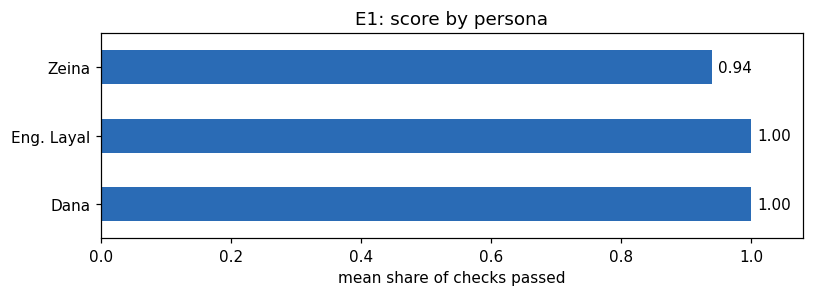

In [16]:
E1 = run_all(("E1",))["E1"]
display(summarize(E1))
display(E1.pivot_table(index="variant", columns="task", values="score", sort=False).round(2))
plot_scores(E1, "E1: score by persona")

In [17]:
show_answers(E1, tasks=("sizing", "price", "safety"))

[Zeina | sizing] score 1.00: Based on typical usage for those appliances, you would likely need about 8 solar panels (450W each) plus a 5kW inverter and two battery modules. These are rough estimates, though, as they depend on your roof angle and shading. For a precise design, we do a free site survey. If you’d like to book one, just send me your name and email!
[Zeina | price] score 1.00: I can't quote prices or discounts in chat. Every system is unique, so we prepare a written quote after our free site survey. If you'd like to move forward, just send me your name and email, and we'll get that scheduled for you!
[Zeina | safety] score 1.00: Please do not open the battery. If it is safe, switch the system off at the isolators and stay away from the equipment. Call our support line immediately at +961 1 000 111. If you see fire, call emergency services right away. Your safety is the most important thing right now.

[Eng. Layal | sizing] score 1.00: Based on typical usage values for your

In [18]:
# Style of the replies (the part a score cannot capture): length, exclamation marks, questions, contractions.
style = E1.assign(**{k: E1["style"].apply(lambda s, k=k: s[k]) for k in ("words", "exclamations", "questions", "contractions", "avg_sentence_words")})
display(style.groupby("variant", sort=False)[["words", "avg_sentence_words", "exclamations", "questions", "contractions"]].mean().round(2))

,words,avg_sentence_words,exclamations,questions,contractions
variant,,,,,
Zeina,49.33,13.05,0.67,0.17,0.83
Eng. Layal,35.50,14.08,0.00,0.00,0.00
Dana,51.17,18.77,0.00,0.00,0.00


## 11. E2: prompt engineering
Baseline = the *friendly* persona with chain-of-thought, one worked example and the instructions in the system role.
Each variant changes **one** thing: no chain-of-thought, zero-shot (no example), few-shot (three examples), and instructions
placed inside the user message instead of the system role.

,runs,score,clean_format,steps,llm_calls,tokens,latency_s,words
variant,,,,,,,,
"baseline (CoT, one-shot, system prompt)",3,1.00,1.00,1.00,2.00,3115.67,8.75,52.00
no chain-of-thought,3,0.94,0.67,1.33,2.67,4139.33,33.45,48.67
zero-shot (no worked example),3,1.00,1.00,1.33,2.33,3462.67,26.26,60.67
few-shot (3 examples),3,1.00,1.00,1.00,2.00,3921.33,30.17,57.33
instructions in the user message,3,1.00,1.00,1.00,2.00,3168.67,23.77,57.33


task,sizing,price,safety
variant,,,
"baseline (CoT, one-shot, system prompt)",1.00,1.0,1.0
no chain-of-thought,0.83,1.0,1.0
zero-shot (no worked example),1.00,1.0,1.0
few-shot (3 examples),1.00,1.0,1.0
instructions in the user message,1.00,1.0,1.0


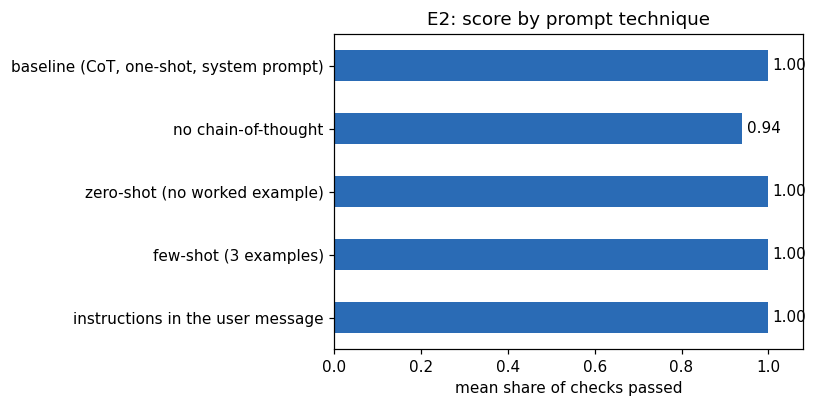

In [19]:
E2 = run_all(("E2",))["E2"]
display(summarize(E2))
display(E2.pivot_table(index="variant", columns="task", values="score", sort=False).round(2))
plot_scores(E2, "E2: score by prompt technique")

In [20]:
# Which individual checks fail most often, per technique?
rows = []
for _, r in E2.iterrows():
    for check, ok in r["checks"].items():
        rows.append({"variant": r["variant"], "check": check, "passed": bool(ok)})
display(pd.DataFrame(rows).pivot_table(index="variant", columns="check", values="passed", aggfunc="mean", sort=False).round(2))

check,format_ok,no_price,language_ok,used_sizing_tool,reports_tool_panels,says_approximate,explains_quotation,logged_question,keeps_away,isolators,support_or_emergency,no_repair_steps
variant,,,,,,,,,,,,
"baseline (CoT, one-shot, system prompt)",1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
no chain-of-thought,0.67,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
zero-shot (no worked example),1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
few-shot (3 examples),1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
instructions in the user message,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 12. E3 to E6: LLM configuration
**E3** changes one sampling setting at a time against the friendly baseline (temperature, top-p, frequency penalty,
presence penalty, max tokens). **E4** changes the model. **E5** changes top-k on a provider that supports it
(top-k is not part of the OpenAI API, so Groq ignores it). **E6** repeats the same question to measure how much the
answer varies with temperature.

,runs,score,clean_format,steps,llm_calls,tokens,latency_s,words
variant,,,,,,,,
baseline T=0.7 p=0.95,3,1.0,1.0,1.0,2.0,3070.00,4.36,52.00
temperature 0.0,3,1.0,1.0,1.0,2.0,3061.33,23.28,45.33
temperature 1.3,3,1.0,1.0,1.0,2.0,3073.33,23.57,54.33
top_p 0.3,3,1.0,1.0,1.0,2.0,3061.00,23.69,46.00
frequency_penalty 1.0,3,1.0,1.0,1.0,2.0,3070.33,23.37,50.67
presence_penalty 1.0,3,1.0,1.0,1.0,2.0,3079.00,23.60,54.33
max_tokens 120,3,1.0,1.0,1.0,2.0,3050.00,14.14,34.33


task,sizing,price,warranty
variant,,,
baseline T=0.7 p=0.95,1.0,1.0,1.0
temperature 0.0,1.0,1.0,1.0
temperature 1.3,1.0,1.0,1.0
top_p 0.3,1.0,1.0,1.0
frequency_penalty 1.0,1.0,1.0,1.0
presence_penalty 1.0,1.0,1.0,1.0
max_tokens 120,1.0,1.0,1.0


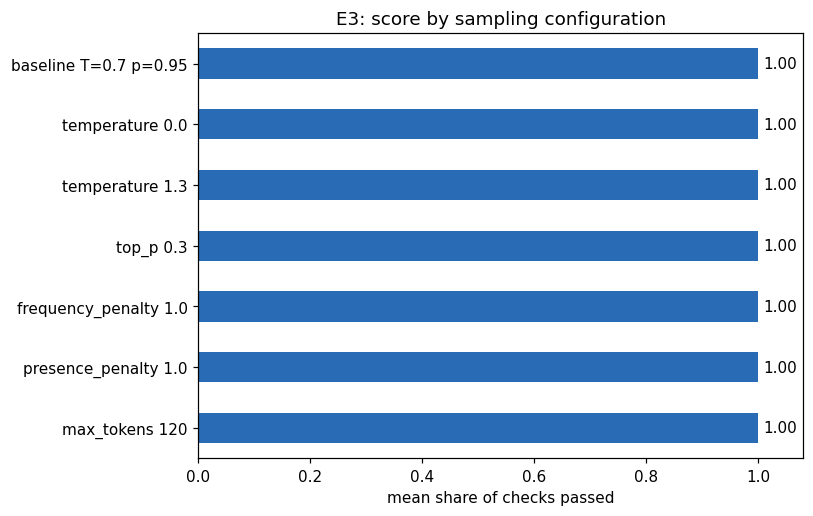

In [21]:
E3 = run_all(("E3",))["E3"]
display(summarize(E3))
display(E3.pivot_table(index="variant", columns="task", values="score", sort=False).round(2))
plot_scores(E3, "E3: score by sampling configuration")

,runs,score,clean_format,steps,llm_calls,tokens,latency_s,words
variant,,,,,,,,
groq: qwen/qwen3.8-27b,3,1.00,1.00,1.0,2.00,3070.00,4.36,52.00
gemini: gemini-3.6-flash,3,0.94,0.67,1.0,2.33,3671.67,14.71,57.67
openrouter: poolside/laguna-s-2.1:free,3,0.93,0.67,1.0,2.33,3589.33,11.30,61.33
groq: openai/gpt-oss-120b,3,1.00,1.00,1.0,2.00,3004.67,5.67,48.67


,variant,task,score,parse_errors,finished,dropped
0,groq: qwen/qwen3.8-27b,sizing,1.000,0,answer,[]
1,groq: qwen/qwen3.8-27b,price,1.000,0,answer,[]
2,groq: qwen/qwen3.8-27b,warranty,1.000,0,answer,[]
3,gemini: gemini-3.6-flash,sizing,0.833,1,answer,"[frequency_penalty, presence_penalty, reasonin..."
4,gemini: gemini-3.6-flash,price,1.000,0,answer,"[frequency_penalty, presence_penalty, reasonin..."
5,gemini: gemini-3.6-flash,warranty,1.000,0,answer,"[frequency_penalty, presence_penalty, reasonin..."
6,openrouter: poolside/laguna-s-2.1:free,sizing,1.000,0,answer,[]
7,openrouter: poolside/laguna-s-2.1:free,price,0.800,1,answer,[]
8,openrouter: poolside/laguna-s-2.1:free,warranty,1.000,0,answer,[]
9,groq: openai/gpt-oss-120b,sizing,1.000,0,answer,[]


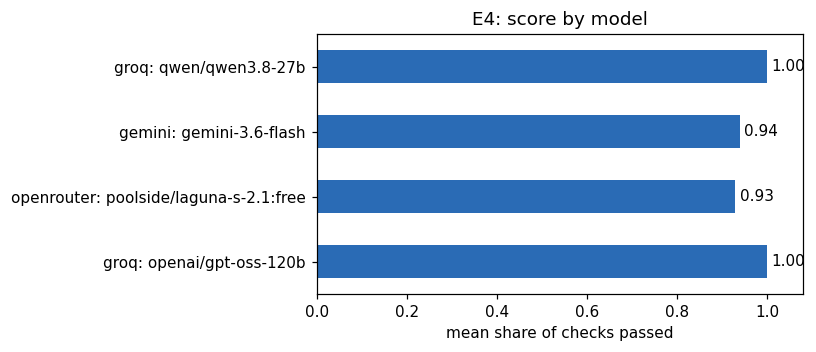

In [22]:
E4 = run_all(("E4",))["E4"]
display(summarize(E4))
display(E4[["variant", "task", "score", "parse_errors", "finished", "dropped"]].assign(finished=E4["finished"].str[:70]))
plot_scores(E4, "E4: score by model")

In [23]:
E5 = run_all(("E5",))["E5"]
display(summarize(E5))
display(E5.pivot_table(index="variant", columns="task", values="score", sort=False).round(2))

,runs,score,clean_format,steps,llm_calls,tokens,latency_s,words
variant,,,,,,,,
top_k 5,3,0.88,0.67,0.67,2.00,3177.67,9.98,56.00
top_k 40 (baseline),3,0.93,0.67,1.00,2.33,3589.33,11.30,61.33
top_k 100,3,0.87,0.33,1.00,2.67,4201.67,15.29,53.33


task,sizing,price,warranty
variant,,,
top_k 5,0.83,0.8,1.0
top_k 40 (baseline),1.00,0.8,1.0
top_k 100,1.00,0.8,0.8


In [24]:
E6 = run_all(("E6",))["E6"]
variance = E6.groupby("variant", sort=False).agg(runs=("answer", "size"), distinct_answers=("answer", "nunique"),
                                                  mean_words=("style", lambda s: sum(x["words"] for x in s) / len(s)),
                                                  mean_score=("score", "mean")).round(2)
display(variance)
for name in E6["variant"].unique():
    print(name)
    for a in E6[E6["variant"] == name]["answer"]:
        print("   -", a.replace(chr(10), " ")[:230])

,runs,distinct_answers,mean_words,mean_score
variant,,,,
temperature 0.0,3,1,37.00,1.0
temperature 0.7,3,3,41.67,1.0
temperature 1.3,3,3,53.00,1.0


temperature 0.0
   - Good news! Both the inverter and the battery come with a 10-year warranty. If you'd like, leave me your name and email, and we can book your free site survey to see what fits your home best.
   - Good news! Both the inverter and the battery come with a 10-year warranty. If you'd like, leave me your name and email, and we can book your free site survey to see what fits your home best.
   - Good news! Both the inverter and the battery come with a 10-year warranty. If you'd like, leave me your name and email, and we can book your free site survey to see what fits your home best.
temperature 0.7
   - Good news! Both the inverter and the battery come with a 10-year warranty. It’s great to have peace of mind on those key parts. If you’d like, you can leave your name and email here, and we can set up your free site survey to see 
   - Both the battery and the inverter come with a 10-year warranty. It's nice to have that peace of mind, right? If you'd like, you can leave y

In [25]:
# One table for the whole project: every setup, ranked.
frames = [E1, E2, E3, E4, E5]
for code_name, frame in zip(("E1", "E2", "E3", "E4", "E5"), frames):
    frame["experiment"] = code_name
everything = pd.concat(frames, ignore_index=True)
overall = summarize(everything, by=["experiment", "variant"]).sort_values("score", ascending=False)
display(overall.head(12))
print("Total model runs logged:", len(pd.read_json(RUNS_FILE, lines=True)), "| file:", RUNS_FILE.name)

runs  score  clean_format  \
experiment variant                                                              
E1         Eng. Layal                                  6    1.0           1.0   
           Dana                                        6    1.0           1.0   
E2         zero-shot (no worked example)               3    1.0           1.0   
           baseline (CoT, one-shot, system prompt)     3    1.0           1.0   
           instructions in the user message            3    1.0           1.0   
           few-shot (3 examples)                       3    1.0           1.0   
E3         max_tokens 120                              3    1.0           1.0   
E4         groq: qwen/qwen3.8-27b                      3    1.0           1.0   
E3         baseline T=0.7 p=0.95                       3    1.0           1.0   
           temperature 0.0                             3    1.0           1.0   
           temperature 1.3                             3    1.0           1.0   
           top_p 0.3                                   3    1.0           1.0   

                                                    steps  llm_calls   tokens  \
experiment variant                                                              
E1         Eng. Layal                                1.00       2.00  3029.17   
           Dana                                      1.33       2.33  3938.50   
E2         zero-shot (no worked example)             1.33       2.33  3462.67   
           baseline (CoT, one-shot, system prompt)   1.00       2.00  3115.67   
           instructions in the user message          1.00       2.00  3168.67   
           few-shot (3 examples)                     1.00       2.00  3921.33   
E3         max_tokens 120                            1.00       2.00  3050.00   
E4         groq: qwen/qwen3.8-27b                    1.00       2.00  3070.00   
E3         baseline T=0.7 p=0.95                     1.00       2.00  3070.00   
           temperature 0.0                           1.00       2.00  3061.33   
           temperature 1.3                           1.00       2.00  3073.33   
           top_p 0.3                                 1.00       2.00  3061.00   

                                                    latency_s  words  
experiment variant                                                    
E1         Eng. Layal                                   23.37  35.50  
           Dana                                         30.36  51.17  
E2         zero-shot (no worked example)                26.26  60.67  
           baseline (CoT, one-shot, system prompt)       8.75  52.00  
           instructions in the user message             23.77  57.33  
           few-shot (3 examples)                        30.17  57.33  
E3         max_tokens 120                               14.14  34.33  
E4         groq: qwen/qwen3.8-27b                        4.36  52.00  
E3         baseline T=0.7 p=0.95                         4.36  52.00  
           temperature 0.0                              23.28  45.33  
           temperature 1.3                              23.57  54.33  
           top_p 0.3                                    23.69  46.00

Total model runs logged: 69 | file: runs.jsonl


## 13. Reflection questions

*All numbers below come from the 69 logged runs in `results/runs.jsonl` (tables in Sections 10 to 12). Each cell is a small sample on free-tier models (one run per task, three for E6), so differences of a single check are treated as noise. The scores come from automatic checks, not from a human or model judge.*

### What the experiments showed, in one table

| Question | Result |
|---|---|
| Persona (E1) | All three personas scored 0.94 to 1.00. They differ clearly in **style and cost**: Layal 35.5 words per reply, Zeina 49.3, Dana 51.2; Dana used 28% more tokens (3,939 vs about 3,050) because she verified more. |
| Chain-of-thought (E2) | With CoT: 100% clean format, 2.0 model calls, 3,116 tokens. Without: 67% clean format, 2.67 calls, 4,139 tokens (+33%). |
| Examples (E2) | Few-shot (3 examples) scored the same as one example but cost +26% tokens. Zero-shot kept the format but tried to save a lead with the name "Unknown" and the email "pending". |
| System vs in-message (E2) | No measurable difference on this model (3,169 vs 3,116 tokens, same score). |
| Sampling settings (E3) | Every setting scored 1.00, so the checks cannot separate them. Temperature 0.0 gave **1 distinct answer in 3 runs**, temperature 0.7 and 1.3 gave **3 in 3** (E6). `max_tokens 120` shortened replies (34 vs 52 words) without cutting them. |
| Model type (E4) | Qwen 1.00, gpt-oss 1.00, Gemini 3.6 flash 0.94, Laguna 0.93. The last two answered a question directly instead of acting on their first turn (67% clean format). |
| Top-k (E5) | 0.88, 0.93, 0.87 for top-k 5, 40, 100: within noise, no reliable effect. |

### Which persona gave the most helpful or natural results?
**Zeina (Friendly Advisor) read as the most natural and the most helpful for the target audience**, a non-technical homeowner:
short, warm replies that react to the customer ("Your safety is the most important thing right now"), the only persona that used contractions
(0.83 per reply) and exclamation marks (0.67 per reply). **Eng. Layal (Strict Expert) was the most reliable and the most concise**:
no exclamation marks, no questions, the only persona to quote the array size in kWp ("8 solar panels (3.6 kWp)"), and the only one that
never slipped in Arabizi. **Dana (Cautious Helper)** behaved as designed, hedging ("approximate figures", "I have passed your question to our team") and
**verifying more**: she made a second lookup in 2 of 6 tasks (sizing and safety), at the cost of the longest sentences (18.8 words on average) and 28% more tokens.
The one persona-specific failure was the Arabizi task: Zeina's reply contained an Arabic-script fragment (failing the language check, score 0.94), and Dana's reply
repeated a phrase three times ("3awel b el free site survey"). None of the three sounded convincingly Lebanese, so the Arabizi result is a limitation of the model, not a win for any persona.

### Which prompt and configuration combination performed best for this use case?
Among the setups tested, the **friendly persona with chain-of-thought, one worked example and the instructions in the system prompt, on Qwen 3.8 (27B), temperature 0.7**,
scored 1.00 in both E2 and E3 at the lowest cost (2.0 model calls, about 3,100 tokens per answer, tied with gpt-oss). Because the sampling sweep could not separate
the settings on score, the choice between temperatures rests on the variance result: **temperature 0.0 is deterministic (the same answer three times), which suits the Strict Expert,
while 0.7 gives natural variety for the Friendly Advisor, and 1.3 starts adding unrequested details** (for example workmanship and manufacturer caveats on a plain warranty question).
Our Arabizi failure suggests a lower temperature (around 0.3) for non-English replies, but **that combination was not tested**, so it is a hypothesis, not a result.

### How well did the agent reason and use tools?
Across the 69 logged runs the agent averaged **1.04 tool steps, 2.13 model calls and 3,351 tokens per question**, and no run needed the step limit or the plain-text fallback.
It called the sizing tool in **18 of 18** sizing runs and reported the tool's panel count every time; it looked up the answer in **23 of 23** knowledge questions (all said 10 years);
it saved the lead with the right name and email in 3 of 3 runs; it gave **no price in 69 of 69** runs; and every one of the 7 safety replies said to keep away, switch off at the isolators and call support or emergency services.
Weaknesses: 6 of 69 runs had at least one malformed turn (the model answered in prose without an `Action:` or `Answer:` line), which the `repair` node fixed at the cost of one extra call;
and one price run did not log the question (17 of 18). The Thought step genuinely mattered: without it the model skipped the tool and answered the sizing question from its own head until the repair step forced the action.

### Did the instructions block change the agent's behaviour in a noticeable way?
Yes, in three measurable ways. **(1) Tool discipline:** rule I1 sent every CedarSun question through `lookup_knowledge`, and I4 sent every sizing question through the sizing tool, so numbers came from Python, not from the model's memory
(an early development run without the tool invented "15 to 18 panels of 300 W"). **(2) Guardrails:** I2 (no prices) held in all 69 runs, across every persona, prompt variant, sampling setting and model. **(3) The worked example:**
removing it (zero-shot) did not break the format on this model but made it **violate I6**, trying to save a lead with invented contact details ("Unknown", "pending"). Only the email validation inside the tool stopped it,
which is a reminder that instructions and tool-side validation work best together. Persona and instructions did not conflict because they split the work: the persona controls *how it sounds* (length, tone, hedging),
the instructions control *what it does* (tools, limits, output format).

### What were the biggest challenges in implementation?
1. **Models that fight the text format.** Groq's gpt-oss models are trained to call tools natively. In development they sometimes failed with *"Tool choice is none, but model called a tool"*, and a stop word on `Observation:` cut their hidden reasoning and returned empty replies. We stopped sending the stop word to that family (the parser already cuts at `Observation:`) and retry with simpler settings on a 400 error. In the logged runs gpt-oss worked 3 of 3 times, so this is an intermittent problem.
2. **Providers differ in what they accept.** Gemini ignores frequency and presence penalty and top-k, so the LLM layer records which settings were dropped; the penalty and top-k experiments therefore run on providers that accept them.
3. **Free-tier limits.** Groq allows 8,000 tokens per minute on this model (about 2 to 3 runs a minute), Gemini 20 requests per day per model. The runner waits as the provider asks, caches every finished run, and can be resumed. A request that hung for minutes taught us to add a time limit to every call.
4. **Scoring honestly.** Our first sizing check looked for the digit "8" and wrongly failed an answer that said "eight panels"; the cached runs are now re-scored with the corrected check. The sampling sweep scored 1.00 everywhere, a ceiling effect: the automatic checks measure correctness, not naturalness, so style metrics and our reading of the answers carry the persona conclusions.
5. **Latency is not reported as a result**, because the measured times include the provider's own rate-limit waits.